# 04 — OAS, option cost, effective duration and convexity

For Monte Carlo path $\omega$ (5,000 Hull–White paths, seed 42), payment date $T_k$ (the 25th after each
accrual month) and pool cash flow $CF_k(\omega)$:

$$P(s)=\frac1N\sum_\omega\sum_k CF_k(\omega)\,D_k(\omega)\,e^{-sT_k}$$

- **OAS** solves $P(\text{OAS})=$ clean mid $+$ 30/360 accrued (the model values every future flow).
- **Z-spread** solves the same equation on the zero-volatility path ($\sigma=0$: the same curve, the same
  mortgage-rate model and the same S-curve, with rates on their forwards).
- **Option cost** is $Z-\text{OAS}$.
- **Effective duration and convexity** shift the whole par curve by $\pm25$ bp, re-bootstrap it and reprice
  at fixed OAS with common random numbers:
  $D=(P_--P_+)/(2P_0\Delta)$ and $C=(P_++P_--2P_0)/(P_0\Delta^2)$.
- **Monte Carlo standard errors.** For OAS: delta method. For $D$ and $C$: the pathwise differences.
- **Parameter-uncertainty intervals.** 200 joint draws of the Hull–White (κ, σ) bootstrap, the
  mortgage-model coefficients and the S-curve bootstrap, revalued on common random numbers.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps

ps.apply()
pd.set_option("display.width", 140)
CUSIP = "3140QVLM4"

In [2]:
from run_security_analytics import run_security_analytics, write_results

report, work = run_security_analytics(CUSIP, n_paths=5_000, seed=42, param_draws=200, param_paths=2_000, n_boot=500)
path = write_results(report)
v, pu = report["valuation"], report["parameter_uncertainty"]
print(f"wrote {path.relative_to(ROOT)}")
print(f"trade {report['dates']['trade_date']}, settle {report['dates']['settlement_date']}, "
      f"first payment {report['dates']['first_payment_date']}; clean {report['market']['clean_mid']:.4f} + "
      f"accrued {report['market']['accrued_per_100']:.4f} = dirty {report['market']['dirty_mid']:.4f}")

wrote artifacts/results/3140QVLM4_2026-10-09_valuation.json
trade 2026-10-09, settle 2026-10-14, first payment 2026-11-25; clean 96.3008 + accrued 0.1986 = dirty 96.4994


In [3]:
def row(key, scale, se_key=None):
    return {"estimate": v[key] * scale, "MC se": (v[se_key] * scale) if se_key else np.nan,
            "param CI low": pu[key]["ci95"][0] * scale, "param CI high": pu[key]["ci95"][1] * scale}

headline = pd.DataFrame({
    "OAS (bp)": row("oas", 1e4, "oas_se"),
    "Z-spread (bp)": row("z_spread", 1e4),
    "Option cost (bp)": row("option_cost", 1e4, "option_cost_se"),
    "Effective duration": row("eff_duration", 1, "eff_duration_se"),
    "Effective convexity": row("eff_convexity", 1, "eff_convexity_se"),
    "Month-1 CPR (%)": row("month1_cpr", 100),
    "Lifetime avg CPR (%)": row("avg_cpr_life", 100),
}).T
headline.round(2)

,estimate,MC se,param CI low,param CI high
OAS (bp),34.53,1.77,8.29,58.98
Z-spread (bp),57.81,NaN,41.45,69.45
Option cost (bp),23.27,1.77,8.60,34.17
Effective duration,6.07,0.03,5.55,7.10
Effective convexity,-60.66,4.56,-104.91,67.33
Month-1 CPR (%),4.08,NaN,2.08,6.06
Lifetime avg CPR (%),5.21,NaN,2.67,6.89


In [4]:
bbg = report["bloomberg_benchmark"]
pd.DataFrame({"this model": [v["oas"] * 1e4, v["z_spread"] * 1e4, v["option_cost"] * 1e4],
              "Bloomberg (same day)": [bbg["oas_bps"], bbg["zspread_bps"], bbg["option_cost_bps"]]},
             index=["OAS", "Z-spread", "Option cost"]).round(1)

,this model,Bloomberg (same day)
OAS,34.5,40.4
Z-spread,57.8,76.6
Option cost,23.3,36.2


Bloomberg uses its own curve, implied (not realised) volatility and its own prepayment model, so its levels
are an external reference, not a target. The comparable quantity is option cost. Both are positive and of
similar size.

### Why the old option cost was −27 bp

The old zero-vol run set $\sigma=0$ in a Vasicek model whose $\theta_Q$ had been solved **with**
$\sigma>0$ to hit the 10Y. Removing $\sigma$ also removes the convexity term, which lifts every yield. The
Z-spread was therefore measured on a different, higher curve than the OAS, and a curve that is too high
needs a smaller spread. The numbers below use the old model's own parameters.

In [5]:
def vasicek_yield(r0, kappa, theta, sigma, tau):
    b = (1 - np.exp(-kappa * tau)) / kappa
    log_a = (theta - sigma**2 / (2 * kappa**2)) * (b - tau) - sigma**2 / (4 * kappa) * b**2
    return -(log_a - b * r0) / tau

old = dict(r0=0.0379, kappa=0.09025, theta=0.08460)
taus = np.array([2.0, 5.0, 10.0, 30.0])
pd.DataFrame({"curve used for OAS (sigma=1.354%)": vasicek_yield(sigma=0.013543, tau=taus, **old) * 100,
              "curve used for Z (sigma=0)": vasicek_yield(sigma=0.0, tau=taus, **old) * 100},
             index=pd.Index(taus, name="maturity")).assign(
    **{"gap (bp)": lambda d: (d.iloc[:, 1] - d.iloc[:, 0]) * 100}).round(2)

,curve used for OAS (sigma=1.354%),curve used for Z (sigma=0),gap (bp)
maturity,,,
2.0,4.18,4.19,1.07
5.0,4.65,4.70,5.52
10.0,5.22,5.38,16.39
30.0,6.29,6.85,55.67


Two further effects made the true option value look negligible, so the curve mismatch alone set the sign:

- the old mortgage rate (Vasicek 30Y zero + 150 bp) was 7.79%;
- the S-curve's floor and slope were assumed rather than estimated.

Here the zero-vol and Monte Carlo runs share one curve. With that fixed, a pool whose prepayments ignore
rates has zero option cost to within Monte Carlo error (regression test
`test_option_cost_is_zero_when_prepayment_ignores_rates`).

### Price profile at fixed OAS

Each point is a full 5,000-path revaluation after a parallel par-curve shift. Negative convexity shows up as
the profile bending below the duration line.

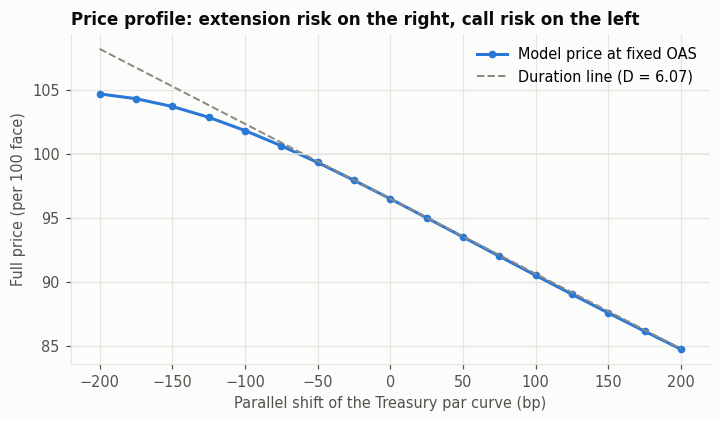

In [6]:
from pricing import path_values, simulate

setup, curve, assumptions = work["setup"], work["models"]["curve"], work["assumptions"]
shifts = np.arange(-200, 201, 25) / 1e4
prices = [path_values(simulate(setup, curve.shifted(s), assumptions, 5_000, 42), v["oas"]).mean()
          / setup.current_face * 100 for s in shifts]
p0 = report["market"]["dirty_mid"]
fig, ax = plt.subplots(figsize=(7.5, 3.9))
ax.plot(shifts * 1e4, prices, color=ps.SERIES[0], marker="o", markersize=4, label="Model price at fixed OAS")
ax.plot(shifts * 1e4, p0 * (1 - v["eff_duration"] * shifts), color=ps.REFERENCE, linestyle="--", linewidth=1.3,
        label=f"Duration line (D = {v['eff_duration']:.2f})")
ax.axhline(100, color=ps.GRID, linewidth=1)
ax.set(xlabel="Parallel shift of the Treasury par curve (bp)", ylabel="Full price (per 100 face)",
       title="Price profile: extension risk on the right, call risk on the left")
ax.legend(loc="upper right")
_ = ps.save(fig, "04_price_profile")

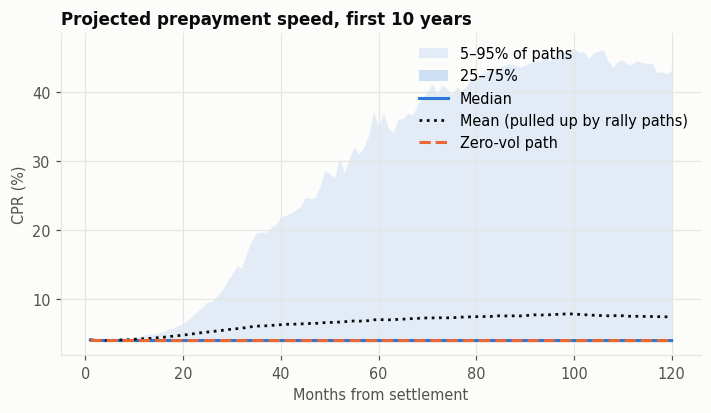

In [7]:
sim, det = work["sim"], work["zero_vol_sim"]
months = np.arange(1, 121)
cpr = sim["cpr"][:, :120] * 100
q = np.percentile(cpr, [5, 25, 50, 75, 95], axis=0)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.fill_between(months, q[0], q[4], color=ps.SERIES[0], alpha=0.12, linewidth=0, label="5–95% of paths")
ax.fill_between(months, q[1], q[3], color=ps.SERIES[0], alpha=0.22, linewidth=0, label="25–75%")
ax.plot(months, q[2], color=ps.SERIES[0], label="Median")
ax.plot(months, cpr.mean(axis=0), color=ps.INK, linestyle=":", linewidth=1.8, label="Mean (pulled up by rally paths)")
ax.plot(months, det["cpr"][0, :120] * 100, color=ps.SERIES[1], linestyle="--", label="Zero-vol path")
ax.set(xlabel="Months from settlement", ylabel="CPR (%)", title="Projected prepayment speed, first 10 years")
ax.legend(loc="upper right")
_ = ps.save(fig, "04_cpr_fan")

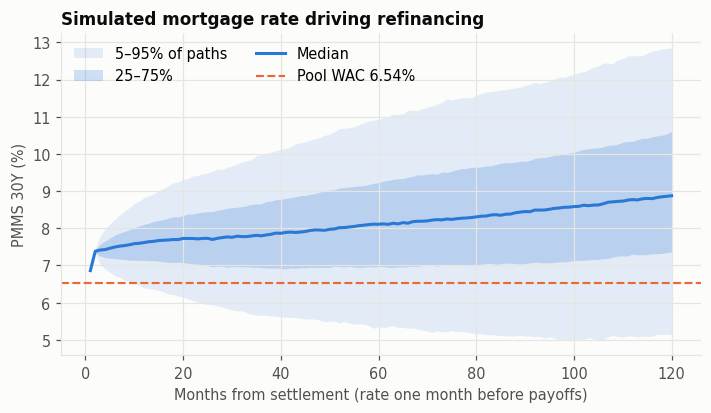

In [8]:
rate = sim["mortgage_rate"][:, :120] * 100
q = np.percentile(rate, [5, 25, 50, 75, 95], axis=0)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.fill_between(months, q[0], q[4], color=ps.SERIES[0], alpha=0.12, linewidth=0, label="5–95% of paths")
ax.fill_between(months, q[1], q[3], color=ps.SERIES[0], alpha=0.22, linewidth=0, label="25–75%")
ax.plot(months, q[2], color=ps.SERIES[0], label="Median")
ax.axhline(setup.wac * 100, color=ps.SERIES[1], linestyle="--", linewidth=1.4, label=f"Pool WAC {setup.wac * 100:.2f}%")
ax.set(xlabel="Months from settlement (rate one month before payoffs)", ylabel="PMMS 30Y (%)",
       title="Simulated mortgage rate driving refinancing")
ax.legend(loc="upper left", ncol=2)
_ = ps.save(fig, "04_mortgage_rate_fan")

### Sensitivity to choices the data cannot settle

- **S-curve ceiling.** Not identified; 35% and 65% vs the base 50%.
- **Pooled S-curve.** One curve for all pools instead of pool-specific floors.
- **Curve without the 20Y CMT.** The 20-year bond trades cheap to the curve, which kinks the 10–30Y forwards.
- **Rate vol × 1.2.** Implied vol usually exceeds the realised vol used here.

In [9]:
sens = pd.DataFrame({name: {"OAS (bp)": s["oas"] * 1e4, "Z (bp)": s["z_spread"] * 1e4,
                            "option cost (bp)": s["option_cost"] * 1e4,
                            "duration": s["eff_duration"], "convexity": s["eff_convexity"],
                            "month-1 CPR %": s["month1_cpr"] * 100}
                     for name, s in report["specification_sensitivity"].items()}).T
sens.loc["base"] = [v["oas"] * 1e4, v["z_spread"] * 1e4, v["option_cost"] * 1e4, v["eff_duration"],
                    v["eff_convexity"], v["month1_cpr"] * 100]
sens.round(2)

,OAS (bp),Z (bp),option cost (bp),duration,convexity,month-1 CPR %
ceiling_0.35,35.93,57.83,21.90,6.16,-49.03,4.02
ceiling_0.65,33.58,57.85,24.27,6.01,-68.32,4.10
pooled_scurve,33.06,58.04,24.99,5.94,-70.67,4.20
curve_without_20y,40.33,66.10,25.77,5.98,-63.78,4.08
sigma_x1.2,22.16,57.81,35.64,5.70,-65.09,4.08
base,34.53,57.81,23.27,6.07,-60.66,4.08


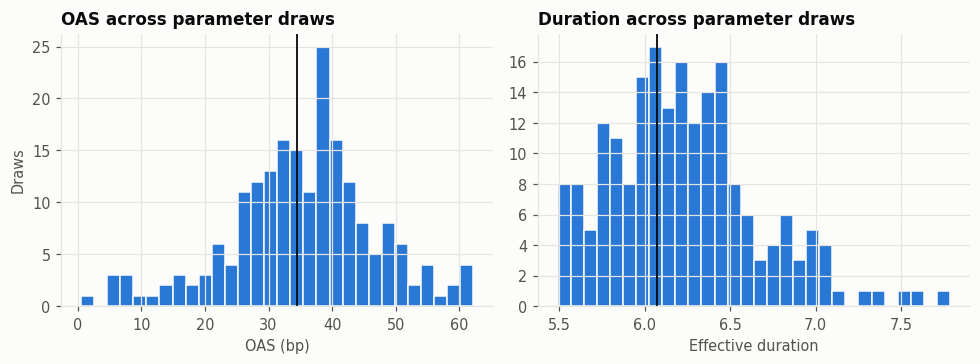

In [10]:
unc = work["uncertainty"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].hist((v["oas"] + unc["oas"]) * 1e4, bins=30, color=ps.SERIES[0], edgecolor=ps.SURFACE, linewidth=1)
axes[0].axvline(v["oas"] * 1e4, color=ps.INK, linewidth=1.2)
axes[0].set(xlabel="OAS (bp)", ylabel="Draws", title="OAS across parameter draws")
axes[1].hist(v["eff_duration"] + unc["eff_duration"], bins=30, color=ps.SERIES[0], edgecolor=ps.SURFACE, linewidth=1)
axes[1].axvline(v["eff_duration"], color=ps.INK, linewidth=1.2)
axes[1].set(xlabel="Effective duration", title="Duration across parameter draws")
fig.tight_layout()
_ = ps.save(fig, "04_parameter_uncertainty")